This Assignment was completed by:
- Bachmann Ryan (bachmrya)
- Bratschi Jonas (bratsjon)
- Dinis Silva Miguel (dinismig)

In [1]:
%%capture
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
!pip install lime
from lime.lime_tabular import LimeTabularExplainer
from lime import submodular_pick
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from collections import defaultdict
from sklearn.metrics import accuracy_score
import shap
import warnings
warnings.filterwarnings('ignore')

# XAI Lab: LIME and SHAP

In [2]:
# Load data
data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target

display(X.head())

# Create training and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale the data
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

# Create DataFrame version with feature names for SHAP
X_test_df = pd.DataFrame(X_test_s, columns=X.columns.tolist())
feature_names = X.columns.tolist()

print(f"Training set: {X_train_s.shape}, Test set: {X_test_s.shape}")
print(f"Classes: {dict(zip(data.target_names, [sum(y_test==0), sum(y_test==1)]))}")

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Training set: (455, 30), Test set: (114, 30)
Classes: {'malignant': 43, 'benign': 71}


Complete the coding exercises below.

## LIME

- **Task (0.5 points):** Select a model (e.g. random forest, gradient boosting, neural network) to address the given task and fit it on the dataset.
- **Task (0.5 points):** Run LIME explainer for the trained model.
- **Task (1 point):** Run local explanations for 4 test samples of your choice from different classes.
- **Task (1 point):** Barplot of the top 5 most influential and top 5 least influential global features created by averaging the feature importances from 100 randomly chosen test samples. Looking at the bar plot of the least influential global features, do you think these features are genuinely uninformative for cancer diagnosis, or could the model be underutilising potentially relevant signals?
- **Task (1 point):** Plot a global overview of the most important features for the model's predictions for the same 100 randomly chosen test samples in the previous task using SP-LIME.
- **Task (1 point):** Create a heatmap where each row is one of the 100 samples and each column is a feature, with cell colour showing the LIME importance weight. This lets you see at a glance which features drive predictions consistently across samples and which vary. Does the heatmap reveal consistent or varying importance of features across samples?

### Coding Tasks

**Task (0.5 points):** Select a model (e.g. random forest, gradient boosting, neural network) to address the given task and fit it on the dataset.

In [3]:
# Your solution here...
# Train a Random Forest classifier
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train_s, y_train)

y_pred = rf.predict(X_test_s)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")

Accuracy: 0.9649


**Task (0.5 points):** Run LIME explainer for the trained model.

In [4]:
# Your solution here...
explainer = LimeTabularExplainer(
    X_train_s,
    feature_names=feature_names,
    class_names=data.target_names.tolist(),
    mode='classification',
    random_state=42
)


**Task (1 point):** Run local explanations for 4 test samples of your choice from different classes.


--- Sample 1 | True: malignant | Pred: malignant ---


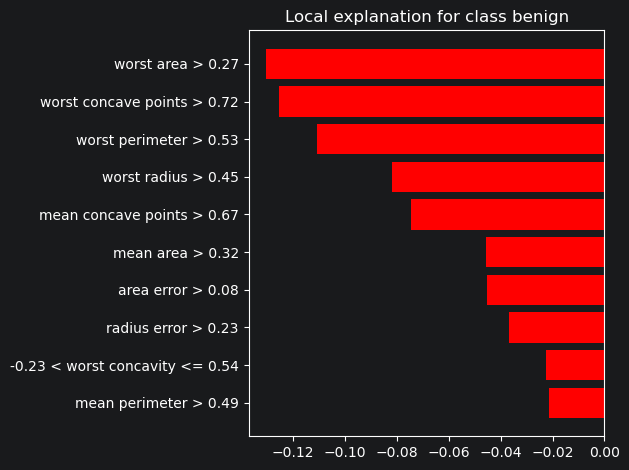


--- Sample 2 | True: malignant | Pred: malignant ---


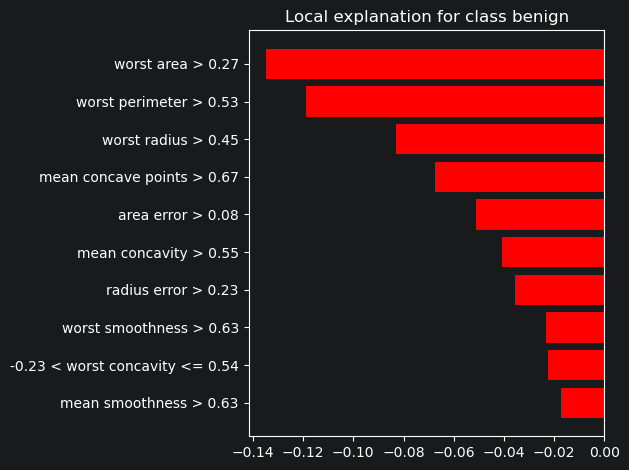


--- Sample 0 | True: benign | Pred: benign ---


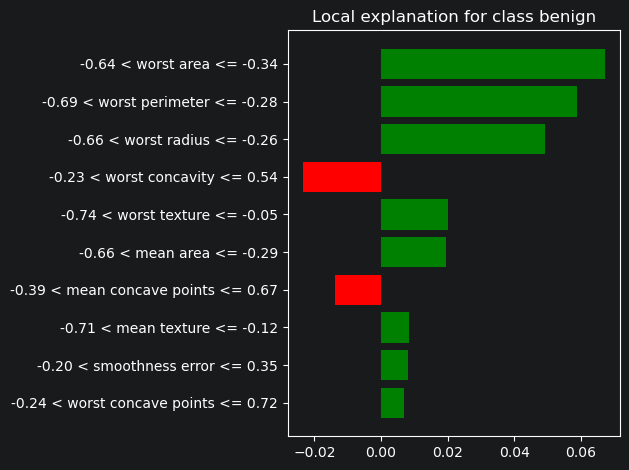


--- Sample 3 | True: benign | Pred: benign ---


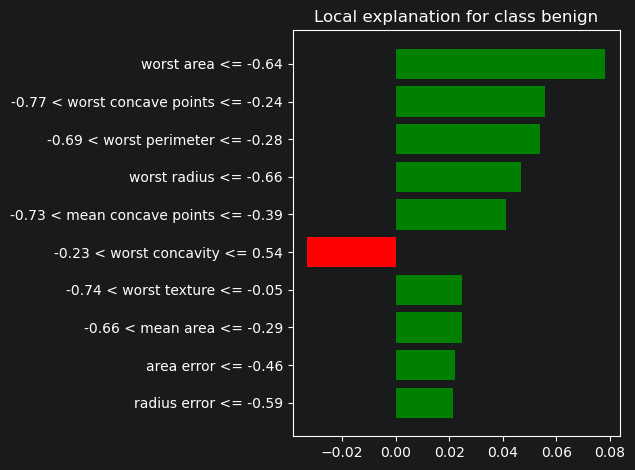

In [5]:
# Your solution here...
#2 malignant (class 0) and 2 benign (class 1) samples
malignant_idx = np.where(y_test.values == 0)[0][:2]
benign_idx = np.where(y_test.values == 1)[0][:2]
sample_indices = np.concatenate([malignant_idx, benign_idx])

for i in sample_indices:
    exp = explainer.explain_instance(X_test_s[i], rf.predict_proba, num_features=10)
    print(f"\n--- Sample {i} | True: {data.target_names[y_test.values[i]]} | Pred: {data.target_names[rf.predict(X_test_s[i].reshape(1,-1))[0]]} ---")
    fig = exp.as_pyplot_figure()
    plt.tight_layout()
    plt.show()

**Task (1 point):** Barplot of the top 5 most influential and top 5 least influential global features created by averaging the feature importances from 100 randomly chosen test samples. Looking at the bar plot of the least influential global features, do you think these features are genuinely uninformative for cancer diagnosis, or could the model be underutilising potentially relevant signals?

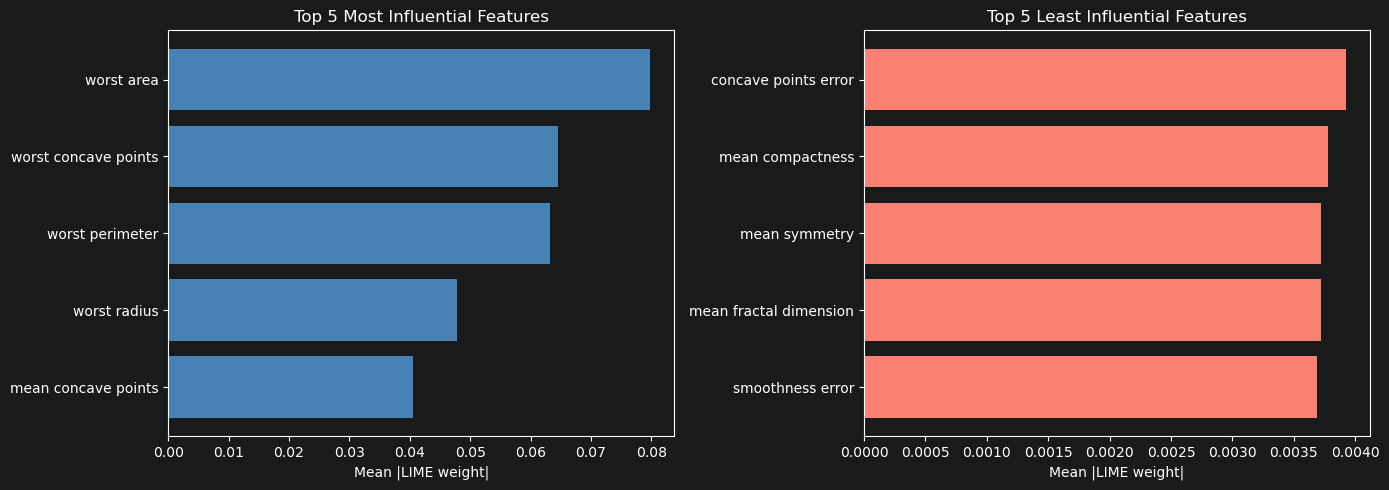

In [6]:
# Your solution here...
np.random.seed(42)
random_100 = np.random.choice(len(X_test_s), size=100, replace=False)

importance_dict = defaultdict(list)
for i in random_100:
    exp = explainer.explain_instance(X_test_s[i], rf.predict_proba, num_features=len(feature_names))
    for feat, weight in exp.as_list():
        # Extract feature name (LIME formats as "feature < val" etc.)
        for fn in feature_names:
            if fn in feat:
                importance_dict[fn].append(abs(weight))
                break

avg_importance = {feat: np.mean(vals) for feat, vals in importance_dict.items()}
sorted_feats = sorted(avg_importance.items(), key=lambda x: x[1], reverse=True)

top5 = sorted_feats[:5]
bottom5 = sorted_feats[-5:]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].barh([f[0] for f in top5][::-1], [f[1] for f in top5][::-1], color='steelblue')
axes[0].set_title('Top 5 Most Influential Features')
axes[0].set_xlabel('Mean |LIME weight|')

axes[1].barh([f[0] for f in bottom5][::-1], [f[1] for f in bottom5][::-1], color='salmon')
axes[1].set_title('Top 5 Least Influential Features')
axes[1].set_xlabel('Mean |LIME weight|')

plt.tight_layout()
plt.show()



Possible Explanation:

The least influential features (concave points error, mean compactness, mean symmetry,
mean fractal dimension, smoothness error) are likely not genuinely uninformative.
Features like symmetry and compactness are medically relevant for cancer diagnosis.
The model may be underutilising these signals, as the Random Forest is dominated
by the strong "worst"-features, pushing the subtler ones into the background.

**Task (1 point):** Plot a global overview of the most important features for the model's predictions for the same 100 randomly chosen test samples in the previous task using SP-LIME.

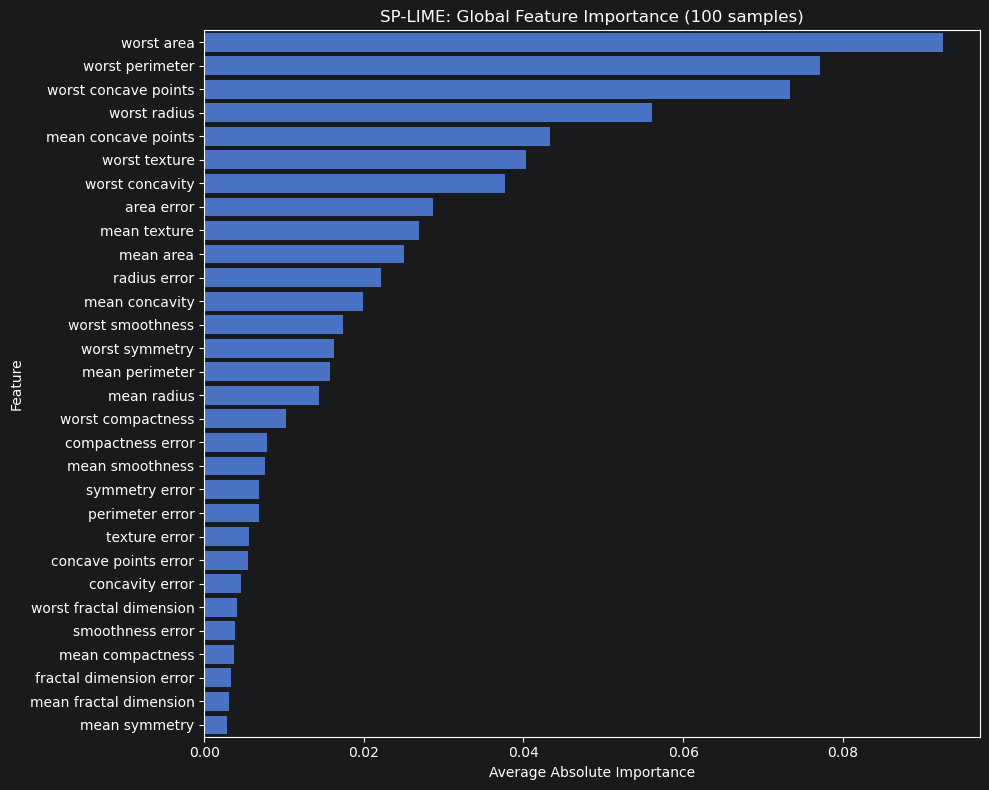

In [7]:
# Your solution here...
from lime import submodular_pick

# SP-LIME global overview
sp = submodular_pick.SubmodularPick(
    explainer,
    X_test_s[random_100],
    rf.predict_proba,
    num_features=len(feature_names),
    num_exps_desired=10
)

# Gewichte aggregieren
sp_importance = defaultdict(list)
for exp in sp.sp_explanations:
    label = list(exp.local_exp.keys())[0]
    for feat, weight in exp.as_list(label=label):
        for fn in feature_names:
            if fn in feat:
                sp_importance[fn].append(abs(weight))
                break

# DataFrame erstellen
sp_df = pd.DataFrame([
    {'Feature': feat, 'Average Importance': np.mean(vals)}
    for feat, vals in sp_importance.items()
]).sort_values('Average Importance', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(x='Average Importance', y='Feature', data=sp_df)
plt.title('SP-LIME: Global Feature Importance (100 samples)')
plt.xlabel('Average Absolute Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

**Task (1 point):** Create a heatmap where each row is one of the 100 samples and each column is a feature, with cell colour showing the LIME importance weight. This lets you see at a glance which features drive predictions consistently across samples and which vary. Does the heatmap reveal consistent or varying importance of features across samples?

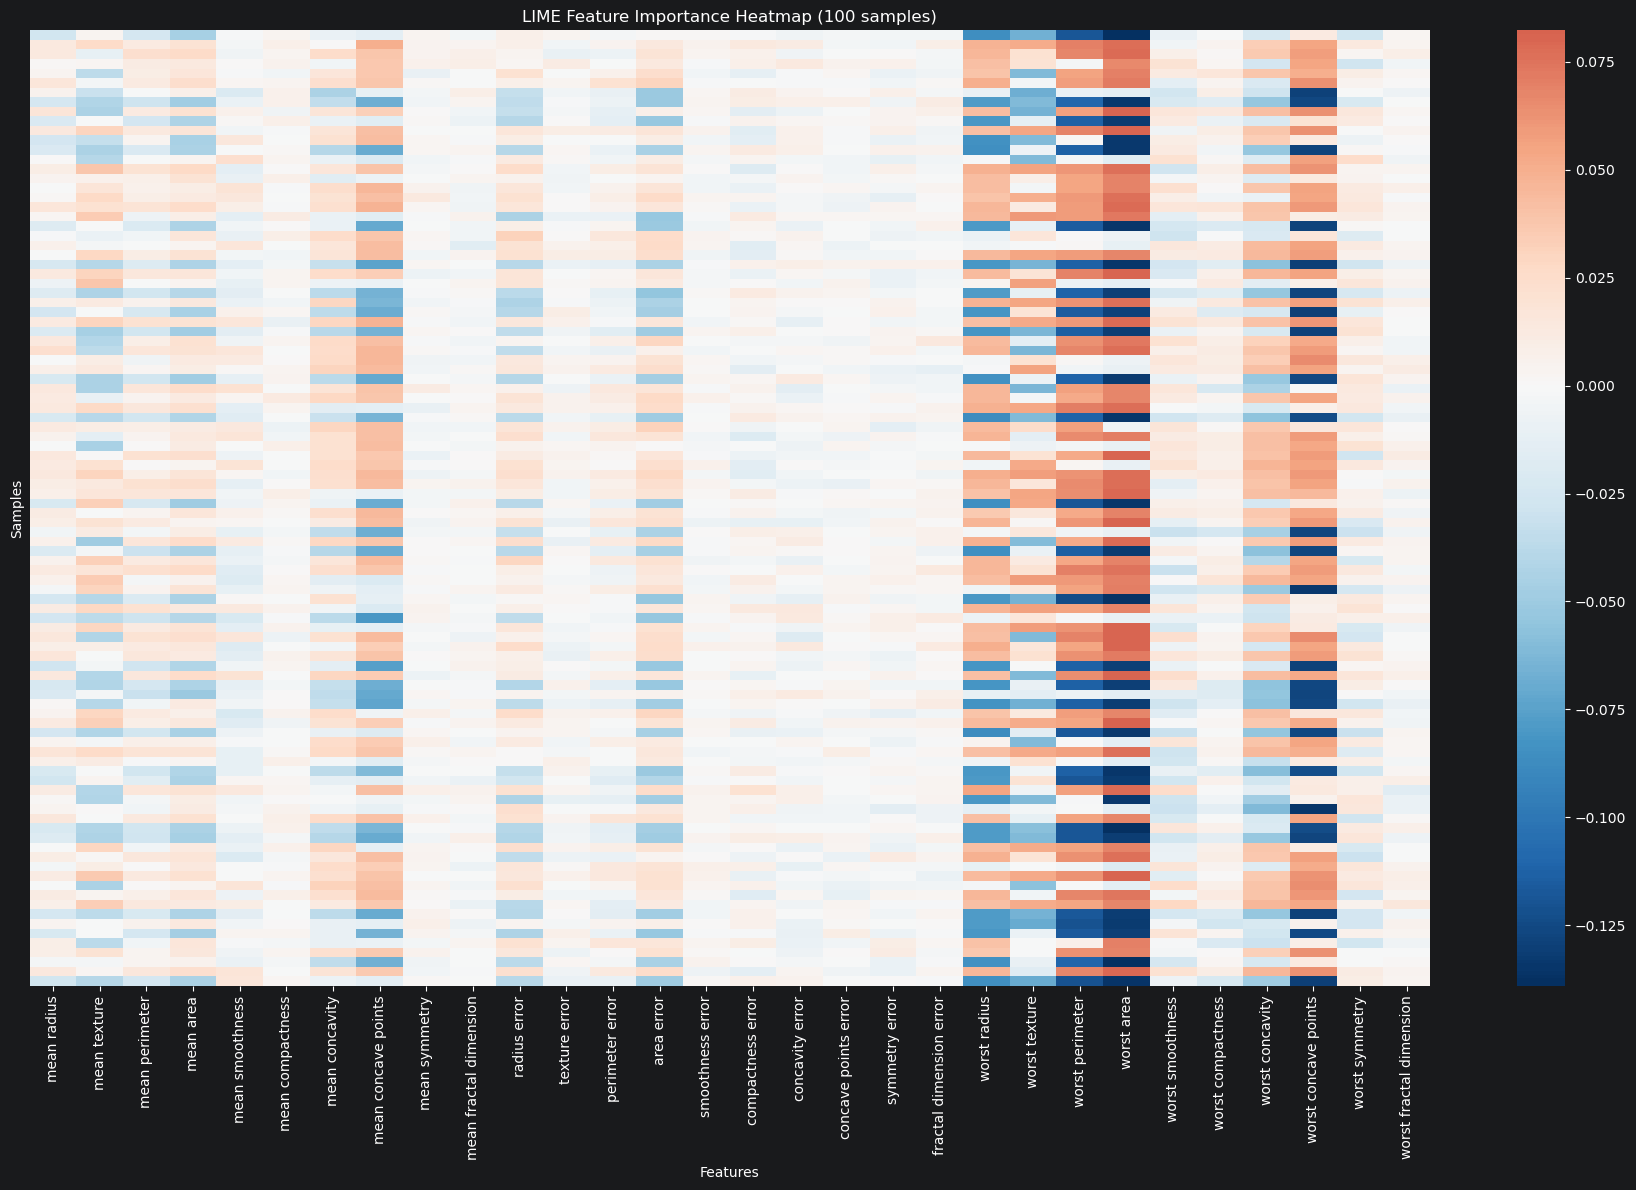

In [8]:
# Your solution here...
heatmap_data = pd.DataFrame(0.0, index=range(100), columns=feature_names)

for idx_row, i in enumerate(random_100):
    exp = explainer.explain_instance(X_test_s[i], rf.predict_proba, num_features=len(feature_names))
    for feat, weight in exp.as_list():
        for fn in feature_names:
            if fn in feat:
                heatmap_data.loc[idx_row, fn] = weight
                break

plt.figure(figsize=(18, 12))
sns.heatmap(heatmap_data, cmap='RdBu_r', center=0, xticklabels=True, yticklabels=False)
plt.title('LIME Feature Importance Heatmap (100 samples)')
plt.xlabel('Features')
plt.ylabel('Samples')
plt.tight_layout()
plt.show()

#Answer:
# The heatmap reveals a mix of consistent and varying importance across samples.
#Features like worst area, worst perimeter and worst concave points show strong,
# consistent colors (deep blue/red) across most samples, indicating they reliably
# drive predictions.

## SHAP

- **Task (1 point):** Apply SHAP explainer on the trained model. Plot a force plot for the same 4 test samples you had selected for LIME.
- **Task (1 point):** Visualize how each feature contributes to the predicted probability of the selected 4 test samples using the waterfall plot. Compare the results to those from LIME for the same samples. What do you observe?
- **Task (0.5 points):** Plot a summary plot (global overview) of how each feature affects the model's prediction for the complete test set.
- **Task (1 point):** Create a SHAP explainer for the same 100 random test samples you used in the LIME task. Plot a global overview of how each feature affects the model prediction. How does this compare to the global explanations from SP-LIME?
- **Task (0.5 points):** Make a data frame that contains the top 5 most influential features for all test samples.
- **Task (1 point):** Plot a dependence plot for two of the most important features: `worst concave points` and `worst area`.

**Task (1 point):** Apply SHAP explainer on the trained model. Plot a force plot for the same 4 test samples you had selected for LIME.

Sample 1, Predicted: malignant


<Figure size 2000x300 with 0 Axes>

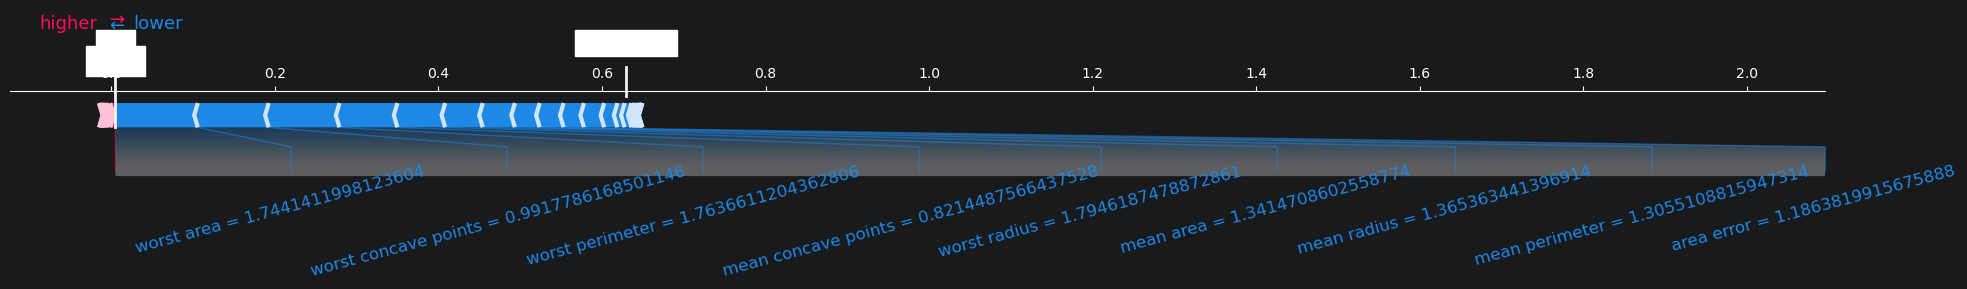

Sample 2, Predicted: malignant


<Figure size 2000x300 with 0 Axes>

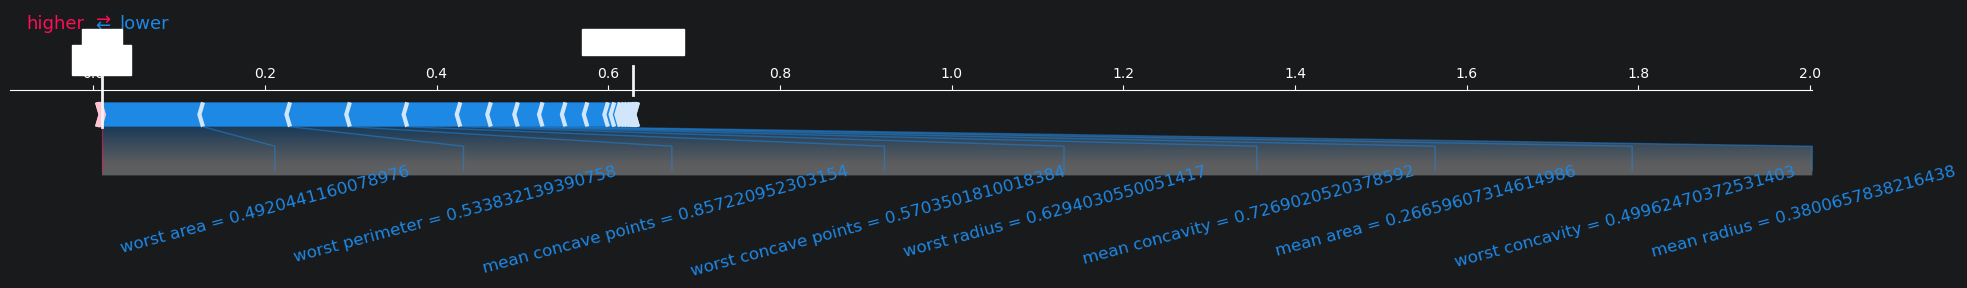

Sample 0, Predicted: benign


<Figure size 2000x300 with 0 Axes>

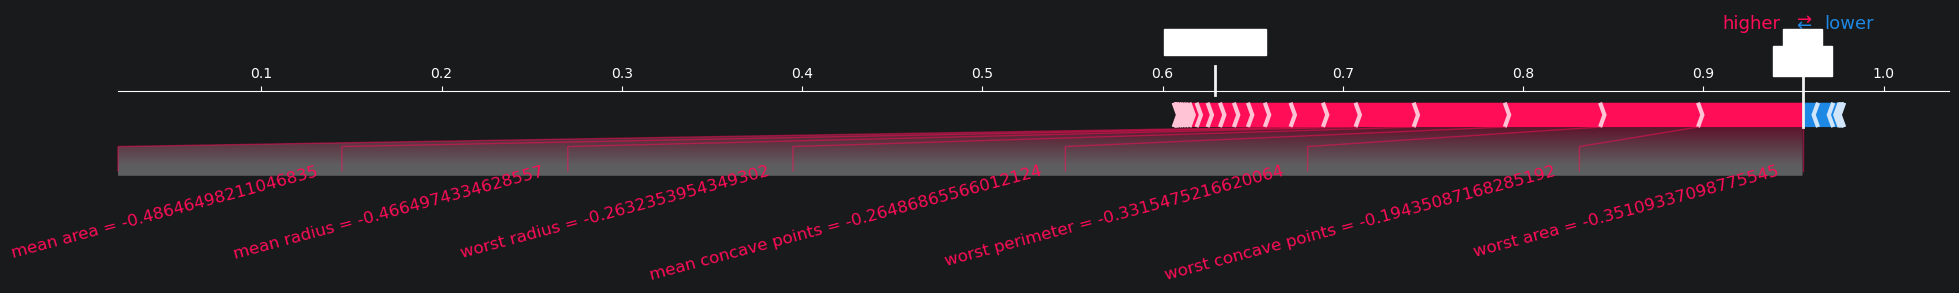

Sample 3, Predicted: benign


<Figure size 2000x300 with 0 Axes>

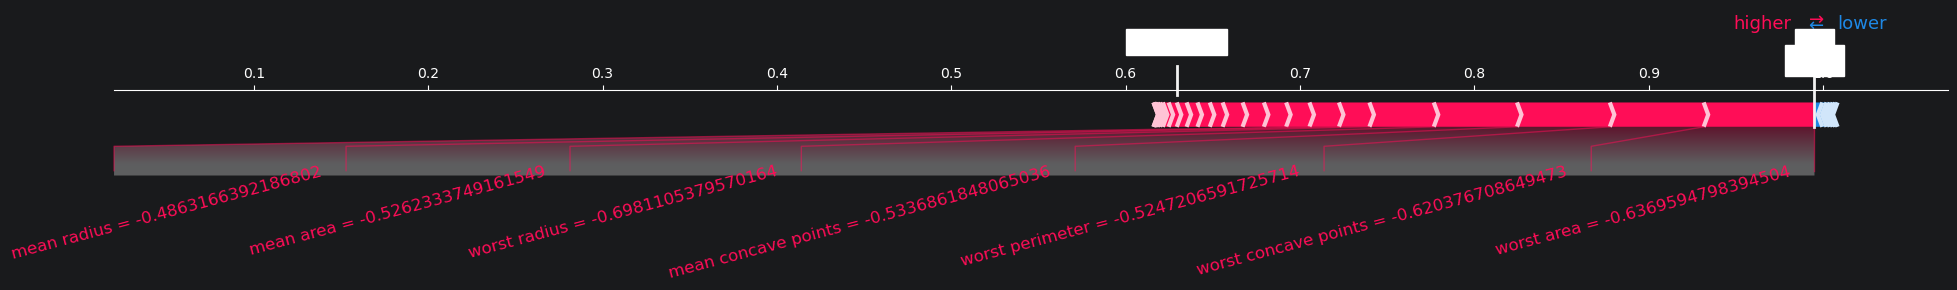

In [9]:
# Your solution here...
shap.initjs()
explainer_shap = shap.TreeExplainer(rf)
shap_values = explainer_shap(X_test_df)

for i in sample_indices:
    pred = rf.predict(X_test_s[i].reshape(1,-1))[0]
    print(f"Sample {i}, Predicted: {data.target_names[pred]}")
    plt.figure(figsize=(20, 3))
    shap.plots.force(shap_values[i, :, 1], matplotlib=True, show=False, text_rotation=15)
    plt.tight_layout()
    plt.show()



**Task (1 point):** Visualize how each feature contributes to the predicted probability of the selected 4 test samples using the waterfall plot. Compare the results to those from LIME for the same samples. What do you observe?

Sample 1, Predicted: malignant


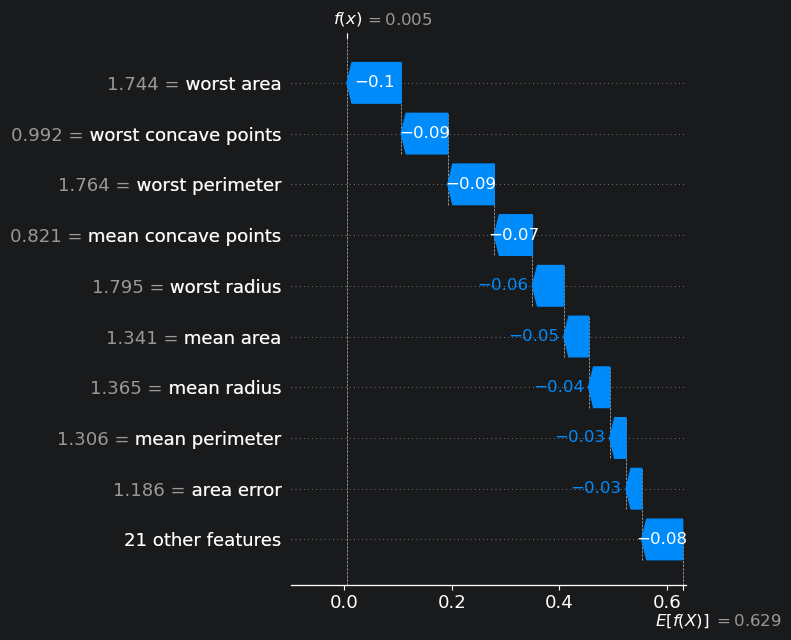

Sample 2, Predicted: malignant


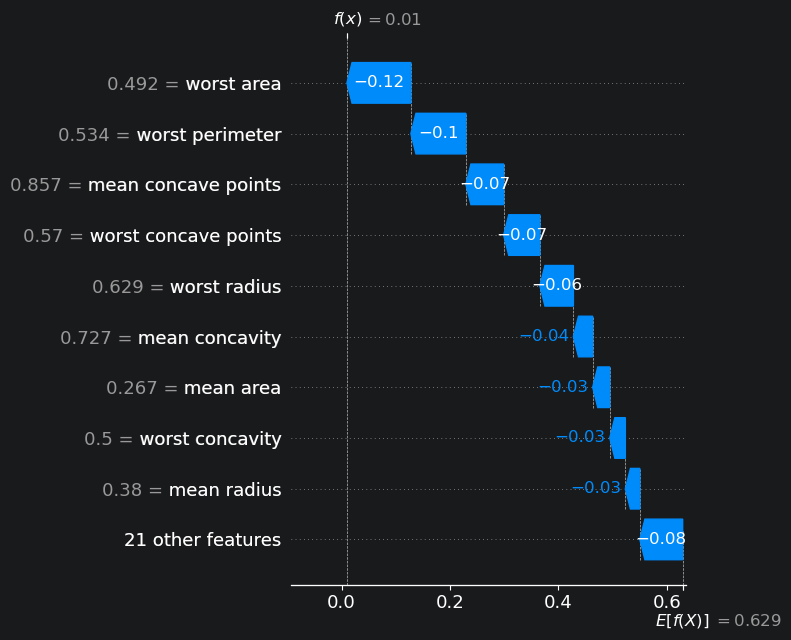

Sample 0, Predicted: benign


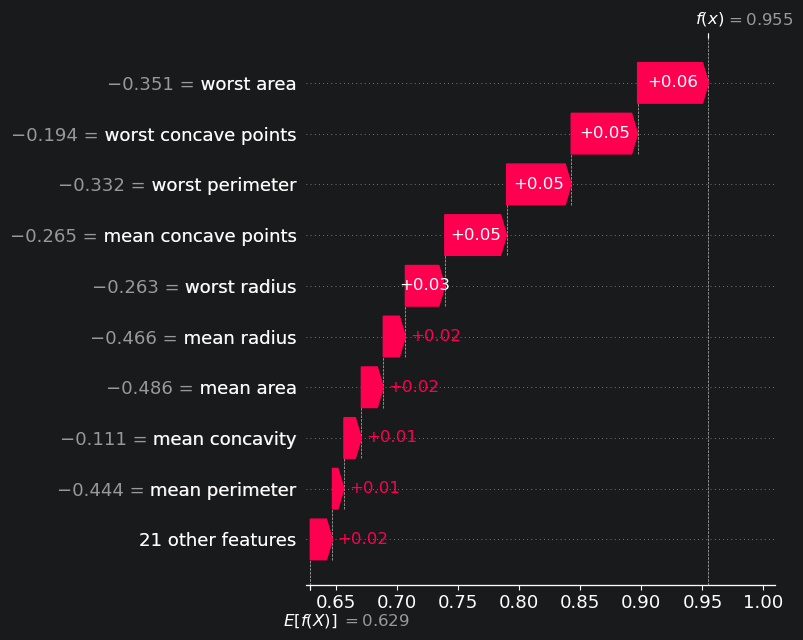

Sample 3, Predicted: benign


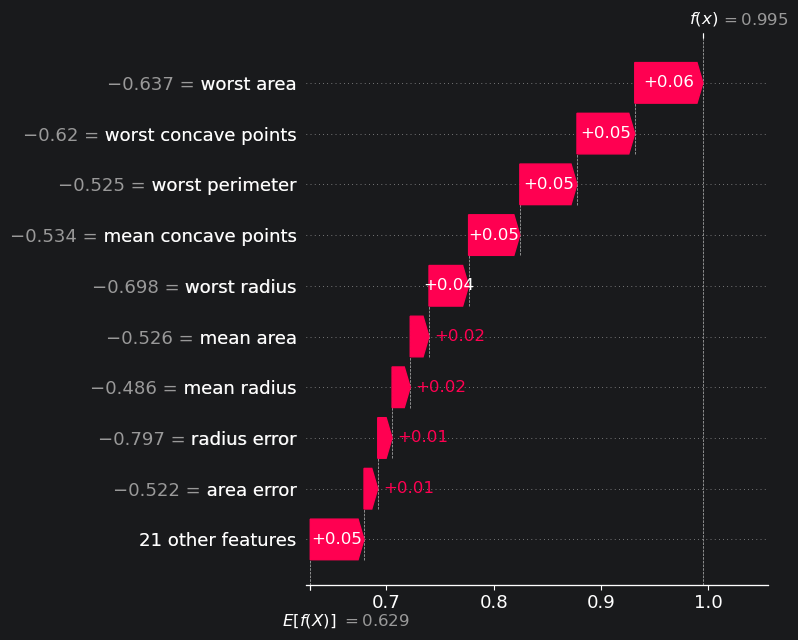

In [10]:
# Your solution here...
for i in sample_indices:
    pred = rf.predict(X_test_s[i].reshape(1,-1))[0]
    print(f"Sample {i}, Predicted: {data.target_names[pred]}")
    shap.plots.waterfall(shap_values[i, :, 1], max_display=10, show=False)
    plt.tight_layout()
    plt.show()




Observations:

 - Beide Methoden (LIME und SHAP) identifizieren dieselben Top-Features als wichtigste
   Einflussfaktoren: worst area, worst concave points und worst perimeter dominieren
   in beiden Methoden konsistent über alle 4 Samples.

 - Bei malignen Samples (Sample 1 & 2): LIME zeigt nur rote Balken (negativ für class benign),
   d.h. alle Features sprechen gegen benign -> Modell sagt malignant.
   SHAP zeigt dasselbe: alle Werte negativ, f(x) ≈ 0.005/0.01 (sehr tiefe malignant-Wahrscheinlichkeit).

 - Bei benignen Samples (Sample 0 & 3): LIME zeigt grüne Balken für worst area, worst perimeter,
  worst radius -> diese sprechen für benign. SHAP bestätigt: alle Werte positiv, f(x) ≈ 0.955/0.995.

 - SHAP ist konsistenter: dieselben Features tauchen in jedem Sample mit ähnlichen
   Gewichtungen auf. LIME variiert stärker, z.B. tauchen bei Sample 2 andere Features
   auf (mean concavity, worst smoothness), die bei Sample 1 nicht erscheinen.

 - LIME gibt Bedingungen aus (z.B. "worst area > 0.27") während SHAP direkte
   numerische Beiträge zeigt -> SHAP ist dadurch präziser und leichter zu interpretieren.

**Task (0.5 points):** Plot a summary plot of how each feature affects the model's prediction for the complete test set.

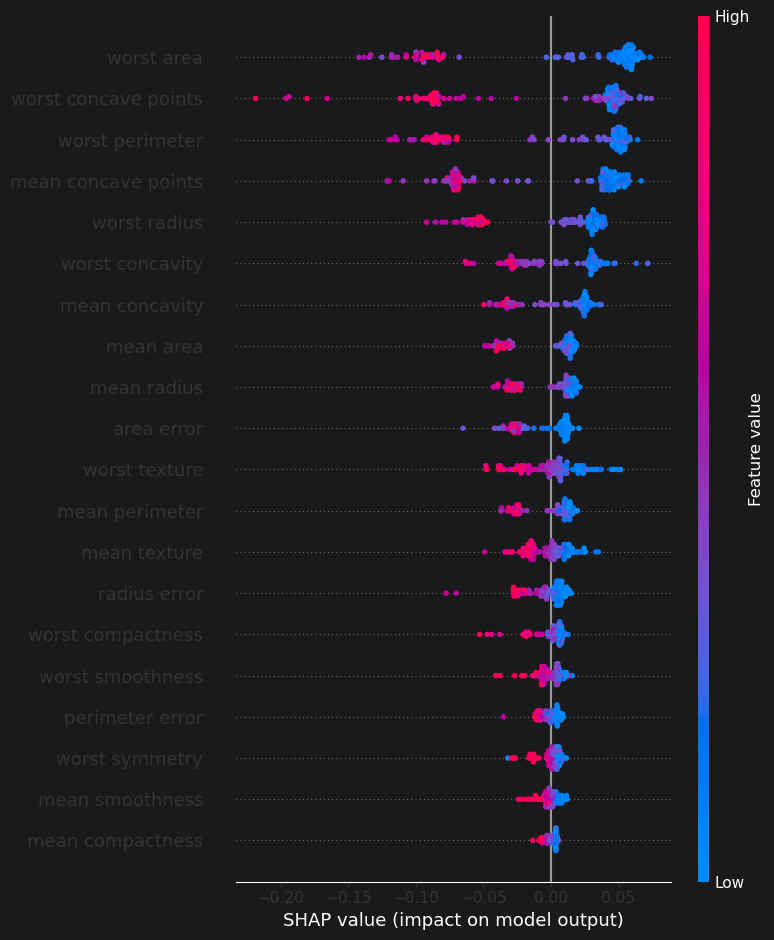

In [11]:
# Your solution here...
shap.summary_plot(shap_values[:, :, 1])

**Task (1 point):** Create a SHAP explainer for the same 100 random test samples you used in the LIME task. Plot a global overview of how each feature affects the model prediction. How does this compare to the global explanations from SP-LIME?

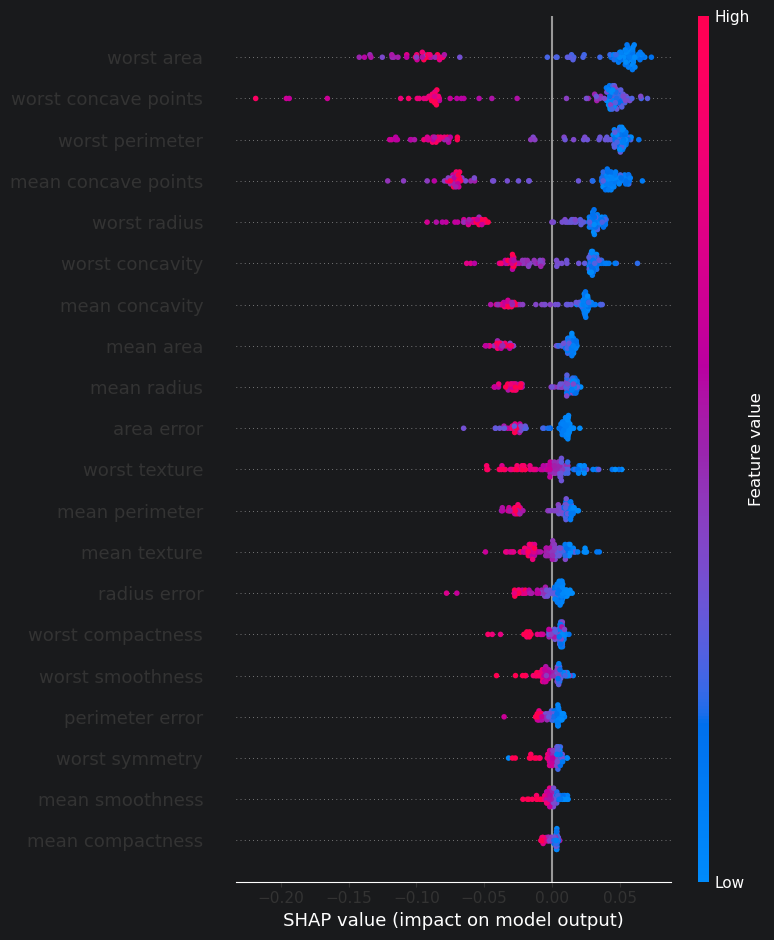

In [12]:
# Your solution here...
shap_values_100 = explainer_shap(X_test_df.iloc[random_100])
shap.summary_plot(shap_values_100[:, :, 1])


# Both SHAP and SP-LIME agree on the most important features: worst area,
# worst concave points and worst perimeter rank at the top in both methods.
# The SHAP summary plot for 100 samples looks nearly identical to the one for
# the full test set, suggesting 100 samples are sufficient to capture the global
# feature importance.

**Task (0.5 points):** Make a data frame that contains the top 5 most influential features for all test samples.

In [13]:
# Your solution here...
shap_df = pd.DataFrame(np.abs(shap_values[:, :, 1].values), columns=feature_names)
mean_importance = shap_df.mean().sort_values(ascending=False)
top5_df = pd.DataFrame({
    'Feature': mean_importance.head(5).index,
    'Mean |SHAP value|': mean_importance.head(5).values
})
display(top5_df)



,Feature,Mean |SHAP value|
0,worst area,0.064997
1,worst concave points,0.063530
2,worst perimeter,0.058727
3,mean concave points,0.055045
4,worst radius,0.038020


**Task (1 point):** Plot a dependence plot for two of the most important features: `worst concave points` and `worst area`.

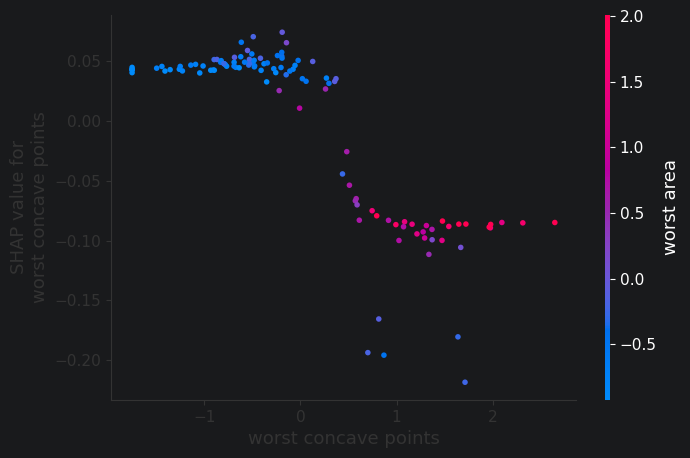

<Figure size 640x480 with 0 Axes>

In [14]:
# Your solution here...

shap.dependence_plot(
    "worst concave points",
    shap_values.values[:, :, 1],
    X_test_df,
    feature_names=feature_names,
    interaction_index="worst area"
)
plt.tight_layout()
plt.show()